In [34]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os

from diffusion_mlp_cnn.models.CNN import CNNDiffusionRegressor
from diffusion_mlp_cnn.models.utils import Data

In [35]:
plt.rcParams.update({
    # "text.usetex": True,
    # "font.family": "serif",
    "text.usetex": False,
    "mathtext.fontset": "stix",
    "font.family": "STIXGeneral",
    "axes.linewidth": 2,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.width": 2,
    "ytick.minor.width": 2,
})

# Load data

### Training and single-step validation data

In [36]:
initializations = ["gaussian", "uniform", "cosine"]
training_data = Data(
    initializations,
    path="training_data",
    model_type="CNN"
)
print(f"Input training data shape (N_samples, Nx): "
      f"{training_data.X_numpy.shape}")
print(f"Output training data shape (N_samples, Nx): "
      f"{training_data.Y_numpy.shape}")
print(f"Training data dtype (input, output): "
      f"({training_data.X.dtype}, {training_data.Y.dtype})")

Input training data shape (N_samples, Nx): (1980, 1, 201)
Output training data shape (N_samples, Nx): (1980, 1, 201)
Training data dtype (input, output): (torch.float32, torch.float32)


In [37]:
validation_data = Data(
    initializations,
    path="validation_data",
    model_type="CNN"
)
print(f"Input single step validation data shape (N_samples, Nx): "
      f"{validation_data.X_numpy.shape}")
print(f"Output single step validation data shape (N_samples, Nx): "
      f"{validation_data.Y_numpy.shape}")
print(f"single step validation data dtype (input, output): "
      f"({validation_data.X.dtype}, {validation_data.Y.dtype})")

Input single step validation data shape (N_samples, Nx): (360, 1, 201)
Output single step validation data shape (N_samples, Nx): (360, 1, 201)
single step validation data dtype (input, output): (torch.float32, torch.float32)


### Full time series data

Initializations: Gaussian, uniform block and cosine

# Training performance

In [38]:
os.makedirs("figures", exist_ok=True)

In [39]:
perf_data = np.loadtxt("cnn_training_perf.txt", dtype=np.float32)
epochs = perf_data[:, 0]
training_MSE_loss = perf_data[:, 1]
training_L2_error = perf_data[:, 2]
validation_L2_error = perf_data[:, 3]

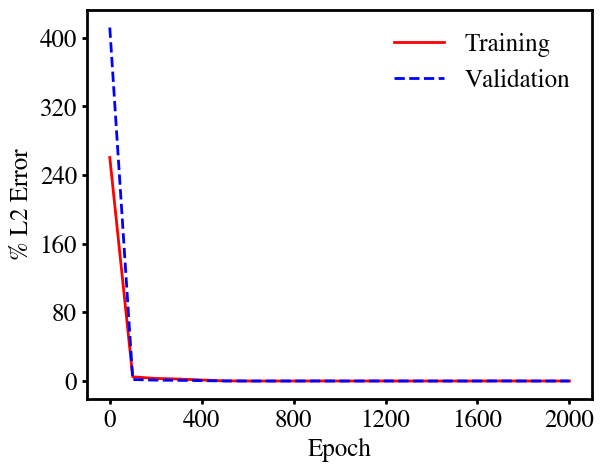

In [40]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(epochs, training_L2_error * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Training")
ax.plot(epochs, validation_L2_error * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Validation")
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.set_xlabel(r"Epoch", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/training_performance_cnn.pdf")
plt.show()

In [41]:
print(f"Minimum single-step validation error")
print(f"ReLU: {np.min(validation_L2_error) * 100:.5f} %")

Minimum single-step validation error
ReLU: 0.00000 %


# Load trained MLP

Saved when the single-step validation error was minimum \
Activations: ReLU, Tanh \
width: 128

In [42]:
cnn_model = CNNDiffusionRegressor(training_data.Nx)
cnn_model.load_state_dict(
    torch.load("cnn.pt", map_location="cpu", weights_only=True)
)
weights = cnn_model.network[0].weight.detach().cpu().numpy().ravel()
bias = cnn_model.network[0].bias.detach().cpu().numpy()
print(f"Weights: {weights}")
print(f"Bias: {bias}")

Weights: [0.4        0.19999999 0.4       ]
Bias: [-2.7693436e-10]


In [43]:
D = 0.4
Fo = D
weights = np.array([Fo, 1 - 2 * Fo, Fo])
print(weights)

[0.4 0.2 0.4]


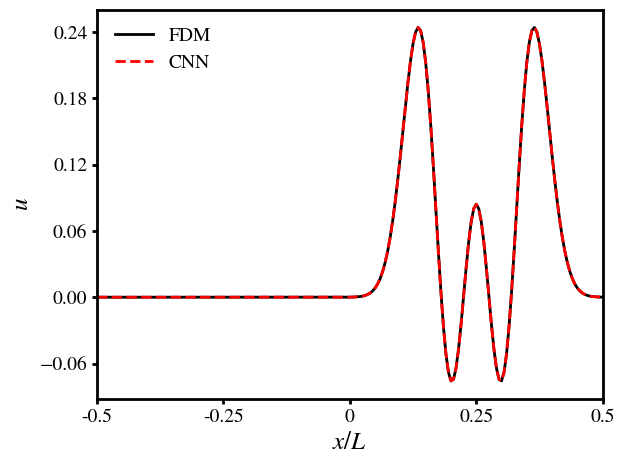

In [44]:
L = 200
n_sample = 359
data = validation_data
Y_check = cnn_model.forward(
    data.X[n_sample]
).detach().numpy()[0]
x = np.linspace(-L/2, L/2, 201)
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(x / L, data.Y[n_sample, 0], linewidth=2, color="black",
        linestyle="solid", label=r"FDM", zorder=1)
ax.plot(x / L, Y_check, linewidth=2, color="red",
        linestyle="dashed", label=r"CNN", zorder=1)
ax.set_xlabel(r"$x / L$", fontsize=18)
ax.set_ylabel(r"$u$", fontsize=18)
ax.set_xlim(-0.5, 0.5)
ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()

# Auto-regressive testing

In [45]:
l2_error_time = {}
mass_err_cnn = {}
mass_err_fdm = {}
u_pred = {}
u_fdm = {}
with torch.inference_mode():
    for init_type in initializations:
        data = np.load("testing_data/" + init_type + ".npz")
        u = data["u"]
        u = u[:, np.newaxis, :]
        Nx = data["Nx"]
        snaps = data["snaps"]
        u_tensor = torch.from_numpy(u)
        u_pred_tensor = u_tensor.clone().detach()
        print(u_pred_tensor.shape)
        for snap in range(1, u_tensor.shape[0]):
            u_pred_tensor[snap] = cnn_model(
                u_pred_tensor[snap - 1]
            )
        diff = u_pred_tensor.detach().numpy() - u
        l2_error = np.linalg.norm(diff, axis=2) /\
            (np.linalg.norm(u, axis=2) + 1e-10)
        l2_error_time.update({init_type: l2_error})
        u_pred.update(
            {init_type: u_pred_tensor.detach().numpy()}
        )
        u_fdm.update({init_type: u})
        mass_fdm = np.sum(u, axis=2)
        mass_err_fdm.update(
            {init_type: (mass_fdm - mass_fdm[0]) / (mass_fdm[0])}
        )
        mass_cnn = np.sum(u_pred[init_type], axis=2)
        mass_err_cnn.update(
            {init_type: (mass_cnn - mass_cnn[0]) / (mass_cnn[0])}
        )
        print(mass_fdm[0])
times = np.arange(0, snaps, 1)  # All must have same time dimension

torch.Size([101, 1, 201])
[1.]
torch.Size([101, 1, 201])
[0.97999996]
torch.Size([101, 1, 201])
[6.3137517]


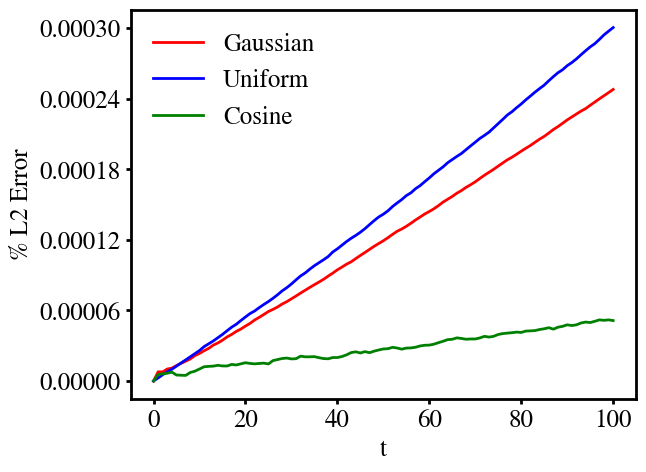

In [46]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, l2_error_time["gaussian"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Gaussian")
ax.plot(times, l2_error_time["uniform"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Uniform")
ax.plot(times, l2_error_time["cosine"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Cosine")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/autoregressive_cnn.pdf")
plt.show()

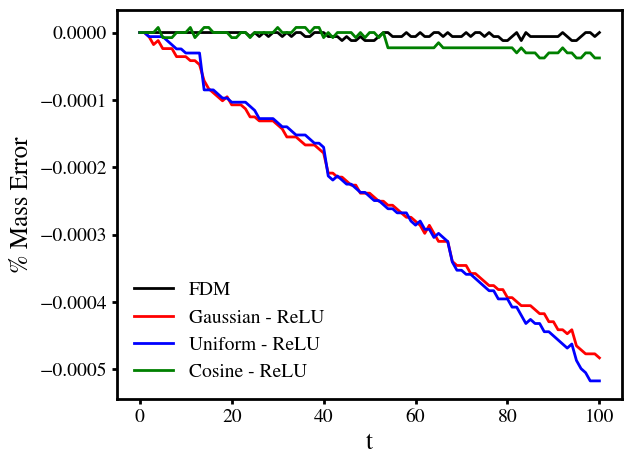

In [47]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, mass_err_fdm["gaussian"] * 100, linewidth=2,
        color="black", linestyle="solid", label=r"FDM")
ax.plot(times, mass_err_cnn["gaussian"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Gaussian - ReLU")
ax.plot(times, mass_err_cnn["uniform"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Uniform - ReLU")
ax.plot(times, mass_err_cnn["cosine"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Cosine - ReLU")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% Mass Error", fontsize=18)
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()

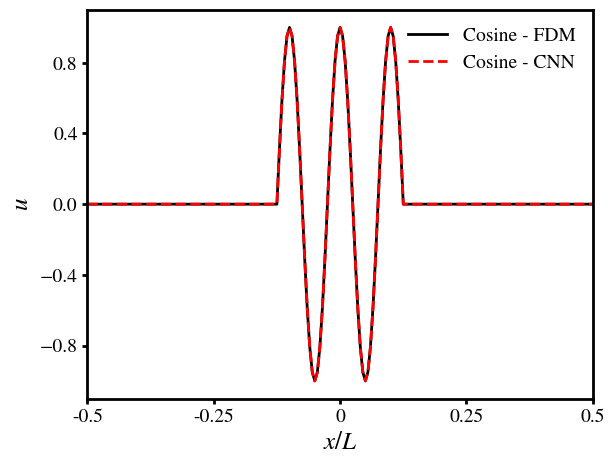

In [48]:
t = 0
init_type = "cosine"
x = np.linspace(-L/2, L/2, 201)
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(x / L, u_fdm[init_type][t, 0], linewidth=2, color="black",
        linestyle="solid", label=init_type.capitalize() + r" - FDM", zorder=1)
ax.plot(x / L, u_pred[init_type][t, 0], linewidth=2, color="red",
        linestyle="dashed", label=init_type.capitalize() + r" - CNN", zorder=1)
ax.set_xlabel(r"$x / L$", fontsize=18)
ax.set_ylabel(r"$u$", fontsize=18)
ax.set_xlim(-0.5, 0.5)
ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()

## Unseen - Multimodal Gaussian

In [49]:
l2_error_time = {}
mass_err_cnn = {}
mass_err_fdm = {}
u_pred = {}
u_fdm = {}
with torch.inference_mode():
    for init_type in ["multimodal"]:
        data = np.load("testing_data/" + init_type + ".npz")
        u = data["u"]
        u = u[:, np.newaxis, :]
        Nx = data["Nx"]
        snaps = data["snaps"]
        u_tensor = torch.from_numpy(u)
        u_pred_tensor = u_tensor.clone().detach()
        print(u_pred_tensor.shape)
        for snap in range(1, u_tensor.shape[0]):
            u_pred_tensor[snap] = cnn_model(
                u_pred_tensor[snap - 1]
            )
        diff = u_pred_tensor.detach().numpy() - u
        l2_error = np.linalg.norm(diff, axis=2) /\
            (np.linalg.norm(u, axis=2) + 1e-10)
        l2_error_time.update({init_type: l2_error})
        u_pred.update(
            {init_type: u_pred_tensor.detach().numpy()}
        )
        u_fdm.update({init_type: u})
        mass_fdm = np.sum(u, axis=2)
        mass_err_fdm.update(
            {init_type: (mass_fdm - mass_fdm[0]) / (mass_fdm[0])}
        )
        mass_cnn = np.sum(u_pred[init_type], axis=2)
        mass_err_cnn.update(
            {init_type: (mass_cnn - mass_cnn[0]) / (mass_cnn[0])}
        )
        print(mass_fdm[0])
times = np.arange(0, snaps, 1)  # All must have same time dimension

torch.Size([101, 1, 201])
[0.99998015]


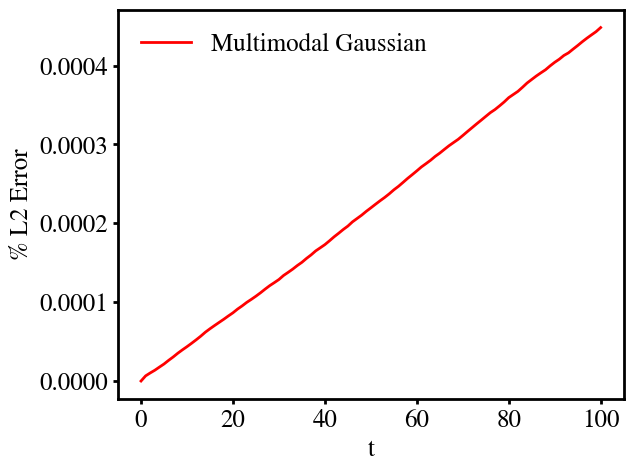

In [50]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, l2_error_time["multimodal"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Multimodal Gaussian")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/autoregressive_cnn_multimodal.pdf")
plt.show()